# 08 - Vuelta al entendimiento de los datos (fase 2 y compuerta G1)

Antes de preparar los datos para el modelo volvimos a la fase de entendimiento de CRISP-DM para revisar tres cosas que dimos por ciertas en la primera entrega.

La primera es la caída de 60 % en los choques. Coincide con el cambio de política de la NYPD, que desde abril de 2020 no exige reportar los choques con solo daños materiales, así que hay que medir a qué series afecta.

La segunda es la gravedad, porque llamábamos grave a cualquier choque con un herido. Aquí revisamos la definición KSI (muertos y lesionados serios) que sale de la tabla de personas.

La tercera es cuáles arrestos miden control vial. Comparamos la regla de la primera entrega, que usaba el texto de `OFNS_DESC`, con el artículo de la ley (`LAW_CODE`).

Al final está la compuerta G1, una prueba para saber si la noche es más letal que el día. De ella depende que el análisis se centre en la noche.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pyspark.sql import functions as F

import noche
from codigos import ARRESTOS_EMBRIAGUEZ_REGEX, ARRESTOS_TRANSITO_REGEX
from config import SILVER, SILVER_FINAL, sesion
from decisiones import (ANIOS_COMPLETOS, FRANJAS_NOCHE, HORA_FIN_NOCHE, HORA_INICIO_NOCHE, KSI_VARIANTE,
                        QUIEBRE_REPORTE)
from estilo import CATEGORICA, TINTA_SECUNDARIA, dec, guardar

spark = sesion("08_entendimiento_noche")
choques = spark.read.parquet(f"{SILVER_FINAL}/choques")
personas = spark.read.parquet(f"{SILVER_FINAL}/personas").filter("tiene_choque")
arrestos = spark.read.parquet(f"{SILVER}/arrestos")

ACENTO = CATEGORICA[0]          # la noche y lo que se quiere resaltar
GRIS = "#b8b7b1"

# KSI por choque: un choque es KSI si al menos una persona lo es
ksi_choque = (personas.groupBy("collision_id").agg(
    F.max(F.col("ksi").cast("int")).alias("ksi"),
    F.max(F.col("ksi_amplia").cast("int")).alias("ksi_amplia"),
    F.sum(F.col("ksi").cast("int")).alias("personas_ksi"),
    F.max(F.col("lesion_sin_detalle").cast("int")).alias("con_lesion_sin_detalle")))
ch = (choques.join(ksi_choque, "collision_id", "left")
      # un choque KSI es siempre un choque con lesionados (así la tasa es una proporción)
      .withColumn("ksi", (F.coalesce("ksi", F.lit(0)) == 1) & F.col("grave"))
      .withColumn("ksi_amplia", (F.coalesce("ksi_amplia", F.lit(0)) == 1) & F.col("grave"))
      .withColumn("con_lesion_sin_detalle", F.coalesce("con_lesion_sin_detalle", F.lit(0)) == 1)
      .withColumn("lesion", F.col("grave"))            # en la primera entrega se llamaba "grave"
      .withColumn("con_muerto", F.coalesce("muertos", F.lit(0)) > 0)
      .withColumn("mes_inicio", F.trunc("fecha", "month"))
      .cache())
print(f"Choques: {ch.count():,} | con lesionados: {ch.filter('lesion').count():,} | KSI ({KSI_VARIANTE}): {ch.filter('ksi').count():,}")

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/11/22 14:52:37 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


26/11/22 14:52:57 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


Choques: 846,508 | con lesionados: 289,280 | KSI (estricta): 19,946


## 1. El quiebre de 2020

Si el cambio de política solo dejó por fuera los choques con daños materiales, los choques con lesionados, los KSI y las muertes no deberían tener el mismo salto. Comparamos el promedio mensual de los 12 meses anteriores a marzo de 2020 con el de 2021.

In [2]:
mensual = (ch.groupBy("mes_inicio").agg(
    F.count("*").alias("choques"), F.sum(F.col("lesion").cast("int")).alias("con_lesionados"),
    F.sum(F.col("ksi").cast("int")).alias("ksi"), F.sum("muertos").alias("muertos"))
    .orderBy("mes_inicio").toPandas())
mensual["mes_inicio"] = pd.to_datetime(mensual["mes_inicio"])

antes = mensual[(mensual["mes_inicio"] >= "2019-03-01") & (mensual["mes_inicio"] < "2020-03-01")]
despues = mensual[mensual["mes_inicio"].dt.year == 2021]
cambio = pd.DataFrame({
    "promedio_mensual_mar2019_feb2020": antes[["choques", "con_lesionados", "ksi", "muertos"]].mean(),
    "promedio_mensual_2021": despues[["choques", "con_lesionados", "ksi", "muertos"]].mean()}).round(0)
cambio["cambio_%"] = (100 * (cambio.iloc[:, 1] / cambio.iloc[:, 0] - 1)).round(1)
cambio.to_csv("../figuras/tabla_08_quiebre_2020.csv")
cambio

,promedio_mensual_mar2019_feb2020,promedio_mensual_2021,cambio_%
choques,17214.0,9213.0,-46.5
con_lesionados,3768.0,3234.0,-14.2
ksi,254.0,211.0,-16.9
muertos,21.0,25.0,19.0


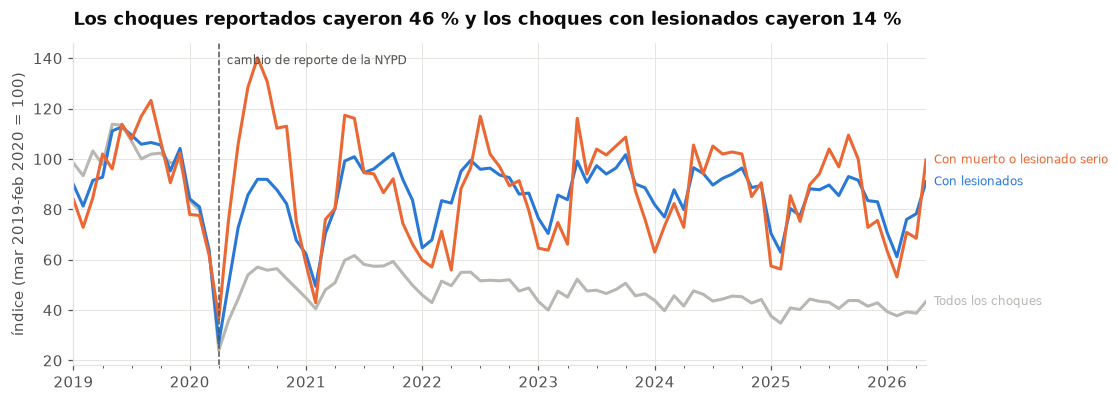

In [3]:
caida_total, caida_lesion = cambio.loc["choques", "cambio_%"], cambio.loc["con_lesionados", "cambio_%"]
fig, ax = plt.subplots(figsize=(10, 3.8))
indice = mensual.set_index("mes_inicio")[["choques", "con_lesionados", "ksi"]]
base = indice[(indice.index >= "2019-03-01") & (indice.index < "2020-03-01")].mean()
(100 * indice / base).plot(ax=ax, color=[GRIS, ACENTO, CATEGORICA[1]], legend=False)
ax.axvline(pd.Timestamp(QUIEBRE_REPORTE), color=TINTA_SECUNDARIA, linestyle="--", linewidth=1)
ax.text(pd.Timestamp(QUIEBRE_REPORTE), ax.get_ylim()[1] * 0.97, "  cambio de reporte de la NYPD",
        fontsize=8, color=TINTA_SECUNDARIA, va="top")
for serie, color, nombre in [("choques", GRIS, "Todos los choques"), ("con_lesionados", ACENTO, "Con lesionados"),
                             ("ksi", CATEGORICA[1], "Con muerto o lesionado serio")]:
    y = (100 * indice[serie] / base[serie]).iloc[-1]
    ax.text(indice.index[-1], y, f"  {nombre}", color=color, fontsize=8, va="center")
ax.set_ylabel("índice (mar 2019-feb 2020 = 100)")
ax.set_xlabel("")
verbo = lambda x: "cayeron" if x < 0 else "subieron"
ax.set_title(f"Los choques reportados {verbo(caida_total)} {abs(caida_total):.0f} % y los choques con lesionados "
             f"{verbo(caida_lesion)} {abs(caida_lesion):.0f} %", pad=12)
guardar(fig, "08_01_quiebre_2020")
plt.show()

Todos los choques cayeron bastante más que los choques con lesionados, y esa diferencia corresponde en buena parte a los choques con solo daños que dejaron de reportarse. La pandemia también movió las series, de modo que la separación es aproximada. Por eso de aquí en adelante la gravedad se calcula sobre los choques con lesionados, que se siguieron reportando.

## 2. Auditoría de la gravedad (KSI)

La tabla de personas trae tres campos de lesión. Revisamos cuánto aporta cada criterio a la definición y cuántos lesionados no tienen detalle. Esos últimos dan la cota superior, que es lo que pasaría si todos fueran serios.

In [4]:
pers = personas.filter(F.col("lesionado"))
aporte = pers.agg(
    F.count("*").alias("lesionados_y_muertos"),
    F.sum(F.col("muerto").cast("int")).alias("muertos"),
    F.sum(F.col("ksi_estricta").cast("int")).alias("ksi_estricta"),
    F.sum(F.col("ksi_amplia").cast("int")).alias("ksi_amplia"),
    F.sum(F.col("lesion_sin_detalle").cast("int")).alias("sin_detalle")).toPandas().T[0]
aporte_pct = (100 * aporte / aporte["lesionados_y_muertos"]).round(2)
auditoria = pd.DataFrame({"personas": aporte.astype(int), "% de los lesionados": aporte_pct})
auditoria.to_csv("../figuras/tabla_08_auditoria_ksi.csv")
auditoria

,personas,% de los lesionados
lesionados_y_muertos,388759,100.00
muertos,1968,0.51
ksi_estricta,21788,5.60
ksi_amplia,24522,6.31
sin_detalle,16776,4.32


In [5]:
por_anio = (personas.filter(F.col("lesionado")).groupBy("anio").agg(
    F.count("*").alias("lesionados"), F.sum(F.col("muerto").cast("int")).alias("muertos"),
    F.sum(F.col("ksi_estricta").cast("int")).alias("ksi_estricta"),
    F.sum(F.col("ksi_amplia").cast("int")).alias("ksi_amplia"),
    F.avg(F.col("lesion_sin_detalle").cast("int")).alias("pct_sin_detalle")).orderBy("anio").toPandas())
por_anio["pct_sin_detalle"] = (100 * por_anio["pct_sin_detalle"]).round(1)
por_anio["ksi_por_100_lesionados"] = (100 * por_anio["ksi_estricta"] / por_anio["lesionados"]).round(2)
por_anio.to_csv("../figuras/tabla_08_ksi_por_anio.csv", index=False)
por_anio

,anio,lesionados,muertos,ksi_estricta,ksi_amplia,pct_sin_detalle,ksi_por_100_lesionados
0,2019,61634,244,3379,3821,3.8,5.48
1,2020,44886,269,3198,3635,3.8,7.12
2,2021,52083,297,2740,3088,3.7,5.26
3,2022,52223,290,2747,3086,4.0,5.26
4,2023,54533,280,2909,3233,4.0,5.33
5,2024,54298,268,2974,3330,5.2,5.48
6,2025,49870,229,2833,3190,5.4,5.68
7,2026,19232,91,1008,1139,5.5,5.24


La definición sirve si los KSI por cada 100 lesionados son parecidos entre años y pocos lesionados quedan sin detalle. La proporción va de 5,2 a 5,7 en todos los años menos 2020 (7,1), y los lesionados sin detalle no pasan de 5,5 %, así que la mantenemos.

## 3. Qué arrestos miden control vial

Los arrestos traen la fecha sin la hora, por eso el control se mide por barrio y por día.

In [6]:
arr = (arrestos
       .withColumn("dwi_ley", noche.col_arresto_dwi(F.col("law_code")))
       .withColumn("transito_ley", noche.col_arresto_transito(F.col("law_code")))
       .withColumn("dwi_texto", F.coalesce(F.upper("ofns_desc").rlike(ARRESTOS_EMBRIAGUEZ_REGEX), F.lit(False)))
       .withColumn("transito_texto", F.coalesce(F.upper("ofns_desc").rlike(ARRESTOS_TRANSITO_REGEX), F.lit(False))))

cruce = arr.groupBy("dwi_ley", "dwi_texto").count().toPandas()
print("Embriaguez: ley (VTL 1192) frente a texto (OFNS_DESC)\n", cruce.pivot(index="dwi_ley", columns="dwi_texto", values="count"))
cruce_t = arr.groupBy("transito_ley", "transito_texto").count().toPandas()
print("\nTránsito: ley (VTL) frente a texto\n", cruce_t.pivot(index="transito_ley", columns="transito_texto", values="count"))

Embriaguez: ley (VTL 1192) frente a texto (OFNS_DESC)
 dwi_texto      False    True 
dwi_ley                      
False      1583996.0      NaN
True           262.0  24251.0



Tránsito: ley (VTL) frente a texto
 transito_texto      False     True 
transito_ley                       
False           1476549.0       NaN
True               9804.0  122156.0


In [7]:
codigos_dwi = (arr.filter("dwi_ley or dwi_texto").groupBy("law_code", "ofns_desc", "pd_desc").count()
               .orderBy(F.desc("count")).limit(25).toPandas())
codigos_dwi.to_csv("../figuras/tabla_08_codigos_embriaguez.csv", index=False)
codigos_dwi

,law_code,ofns_desc,pd_desc,count
0,VTL11920U2,INTOXICATED & IMPAIRED DRIVING,"INTOXICATED DRIVING,ALCOHOL",11526
1,VTL11920U3,INTOXICATED & IMPAIRED DRIVING,"INTOXICATED DRIVING,ALCOHOL",6811
2,VTL1192000,INTOXICATED & IMPAIRED DRIVING,"INTOXICATED DRIVING,ALCOHOL",1512
3,VTL11920E2,INTOXICATED/IMPAIRED DRIVING,"INTOXICATED DRIVING,ALCOHOL",1150
4,VTL11920E3,INTOXICATED/IMPAIRED DRIVING,"INTOXICATED DRIVING,ALCOHOL",706
5,VTL11920U4,INTOXICATED & IMPAIRED DRIVING,"IMPAIRED DRIVING,DRUG",456
6,VTL119202U,INTOXICATED & IMPAIRED DRIVING,"INTOXICATED DRIVING,ALCOHOL",358
7,VTL1192U2C,INTOXICATED & IMPAIRED DRIVING,"INTOXICATED DRIVING,ALCOHOL",338
8,VTL11920D3,INTOXICATED/IMPAIRED DRIVING,"INTOXICATED DRIVING,ALCOHOL",268
9,VTL1192AI1,OTHER TRAFFIC INFRACTION,"TRAFFIC,UNCLASSIFIED INFRACTIO",254


In [8]:
control_anual = arr.filter(F.col("anio").isin(ANIOS_COMPLETOS + [2026])).groupBy("anio").agg(
    F.sum(F.col("dwi_ley").cast("int")).alias("embriaguez_ley"),
    F.sum(F.col("dwi_texto").cast("int")).alias("embriaguez_texto"),
    F.sum(F.col("transito_ley").cast("int")).alias("transito_ley"),
    F.sum(F.col("transito_texto").cast("int")).alias("transito_texto")).orderBy("anio").toPandas()
control_anual.to_csv("../figuras/tabla_08_arrestos_control_anual.csv", index=False)
control_anual

,anio,embriaguez_ley,embriaguez_texto,transito_ley,transito_texto
0,2019,5260,5230,23474,22598
1,2020,2677,2645,8756,8330
2,2021,2763,2716,10142,9612
3,2022,2844,2797,12253,11714
4,2023,3001,2960,18417,17527
5,2024,2892,2866,20462,19001
6,2025,3354,3327,24305,21123
7,2026,1722,1710,14151,12251


Usamos `LAW_CODE` porque cita el artículo de la ley y no depende de cómo se redactó la descripción. La tabla de arriba muestra cuántos casos cambian frente a la regla de la primera entrega.

## 4. Compuerta G1: ¿la noche es más letal?

Medimos los KSI por cada 100 choques con lesionados en cada hora. Como el denominador se reporta igual antes y después de 2020, la medida no depende del cambio de reporte. La calculamos desde 2021 para que todo el periodo tenga las mismas reglas de reporte.

In [9]:
recientes = ch.filter(F.col("anio") >= 2021).filter(F.col("hora").isNotNull())
por_hora = (recientes.groupBy("hora").agg(
    F.count("*").alias("choques"), F.sum(F.col("lesion").cast("int")).alias("con_lesionados"),
    F.sum(F.col("ksi").cast("int")).alias("ksi"), F.sum(F.col("ksi_amplia").cast("int")).alias("ksi_amplia"),
    F.sum(F.col("con_muerto").cast("int")).alias("con_muerto"))
    .orderBy("hora").toPandas().set_index("hora"))
por_hora["ksi_por_100_lesion"] = 100 * por_hora["ksi"] / por_hora["con_lesionados"]
bajo, alto = noche.wilson(por_hora["ksi"], por_hora["con_lesionados"])
por_hora["ic_bajo"], por_hora["ic_alto"] = 100 * bajo, 100 * alto
por_hora["muertes_por_1000_lesion"] = 1000 * por_hora["con_muerto"] / por_hora["con_lesionados"]
promedio = 100 * por_hora["ksi"].sum() / por_hora["con_lesionados"].sum()
por_hora["sobre_promedio"] = por_hora["ic_bajo"] > promedio      # por encima del promedio con confianza
por_hora.round(3).to_csv("../figuras/tabla_08_letalidad_por_hora.csv")

horas_noche = sorted(set(range(HORA_INICIO_NOCHE, 24)) | set(range(0, HORA_FIN_NOCHE + 1)))
sugeridas = por_hora.index[por_hora["sobre_promedio"]].tolist()
print("Horas de la noche definida en decisiones.py:", horas_noche)
print("Horas con letalidad por encima del promedio (IC 95 % completo arriba):", sugeridas)
print(f"Coincidencia: {len(set(sugeridas) & set(horas_noche))} de {len(horas_noche)} horas de la noche definida están sobre el promedio")

Horas de la noche definida en decisiones.py: [0, 1, 2, 3, 4, 5, 21, 22, 23]
Horas con letalidad por encima del promedio (IC 95 % completo arriba): [0, 1, 2, 3, 4, 5, 6, 21, 22, 23]
Coincidencia: 9 de 9 horas de la noche definida están sobre el promedio


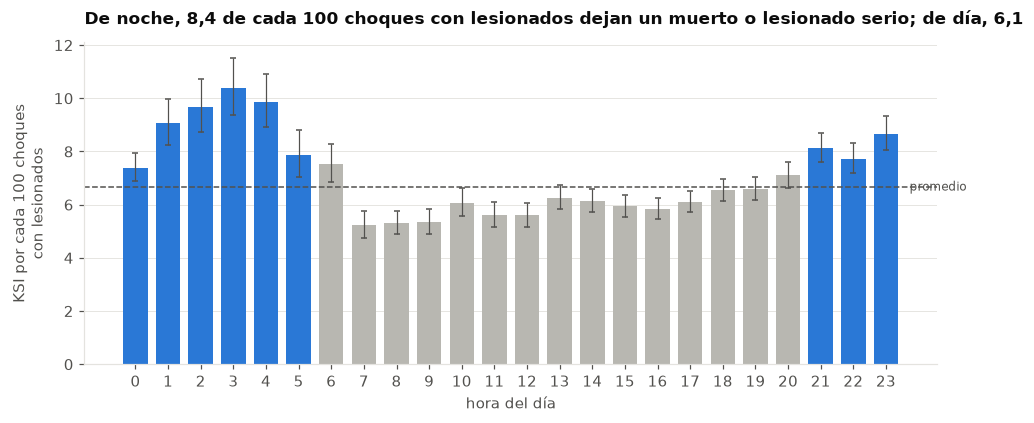

In [10]:
es_noche = por_hora.index.isin(horas_noche)
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.bar(por_hora.index, por_hora["ksi_por_100_lesion"], color=np.where(es_noche, ACENTO, GRIS), width=0.75)
ax.errorbar(por_hora.index, por_hora["ksi_por_100_lesion"],
            yerr=[por_hora["ksi_por_100_lesion"] - por_hora["ic_bajo"], por_hora["ic_alto"] - por_hora["ksi_por_100_lesion"]],
            fmt="none", ecolor=TINTA_SECUNDARIA, elinewidth=0.8, capsize=2)
ax.axhline(promedio, color=TINTA_SECUNDARIA, linestyle="--", linewidth=1)
ax.text(23.6, promedio, " promedio", fontsize=8, color=TINTA_SECUNDARIA, va="center")
ax.set_xticks(range(24))
ax.set_xlabel("hora del día")
ax.set_ylabel("KSI por cada 100 choques\ncon lesionados")
noche_tasa = 100 * por_hora.loc[es_noche, "ksi"].sum() / por_hora.loc[es_noche, "con_lesionados"].sum()
dia_tasa = 100 * por_hora.loc[~es_noche, "ksi"].sum() / por_hora.loc[~es_noche, "con_lesionados"].sum()
ax.set_title(f"De noche, {dec(noche_tasa)} de cada 100 choques con lesionados dejan un muerto o lesionado serio; "
             f"de día, {dec(dia_tasa)}", pad=12, fontsize=11)
ax.grid(axis="x", visible=False)
guardar(fig, "08_02_letalidad_por_hora")
plt.show()

Comparamos la proporción de la noche con la del día con su intervalo de confianza. La prueba se pasa si el intervalo de la razón entre noche y día queda completo por encima de 1 con las dos variantes de KSI.

In [11]:
def razon(columna):
    k_n, n_n = por_hora.loc[es_noche, columna].sum(), por_hora.loc[es_noche, "con_lesionados"].sum()
    k_d, n_d = por_hora.loc[~es_noche, columna].sum(), por_hora.loc[~es_noche, "con_lesionados"].sum()
    p_n, p_d = k_n / n_n, k_d / n_d
    r = p_n / p_d
    # IC del logaritmo de la razón de riesgos (método de Katz)
    ee = np.sqrt((1 - p_n) / k_n + (1 - p_d) / k_d)
    return {"variable": columna, "noche_por_100": 100 * p_n, "dia_por_100": 100 * p_d, "razon": r,
            "ic_bajo": r * np.exp(-1.96 * ee), "ic_alto": r * np.exp(1.96 * ee)}

g1 = pd.DataFrame([razon("ksi"), razon("ksi_amplia"), razon("con_muerto")]).round(4)
g1.to_csv("../figuras/tabla_08_compuerta_g1.csv", index=False)
print(g1.to_string(index=False))
supera = bool((g1.loc[g1["variable"].isin(["ksi", "ksi_amplia"]), "ic_bajo"] > 1).all())
print("\nCOMPUERTA G1:", "SUPERADA: la noche es más letal; la historia sigue igual." if supera else
      "NO SUPERADA: reformular el eje hacia 'franjas de mayor letalidad' antes de seguir.")

  variable  noche_por_100  dia_por_100  razon  ic_bajo  ic_alto
       ksi         8.4205       6.0740 1.3863   1.3396   1.4346
ksi_amplia         9.2635       6.8391 1.3545   1.3113   1.3991
con_muerto         1.1699       0.4932 2.3722   2.1350   2.6359

COMPUERTA G1: SUPERADA: la noche es más letal; la historia sigue igual.


## 5. ¿Falta más la causa de noche?

Si la causa faltara más de noche, la comparación del alcohol entre noche y día quedaría sesgada. En cualquier caso lo que se mide de alcohol es un piso. Lo calculamos sobre los choques con lesionados desde 2021.

In [12]:
sin_causa = noche.col_sin_causa(F.col("factor_1"))
causas = (recientes.filter("lesion")
          .withColumn("franja", noche.col_franja(F.col("hora")))
          .groupBy("franja").agg(F.count("*").alias("con_lesionados"),
                                 F.avg(sin_causa.cast("int")).alias("pct_sin_causa"))
          .orderBy("franja").toPandas())
causas["etiqueta"] = causas["franja"].map(noche.ETIQUETAS_FRANJA)
causas["pct_sin_causa"] = (100 * causas["pct_sin_causa"]).round(1)
causas["es_noche"] = causas["franja"].isin(FRANJAS_NOCHE)
causas.to_csv("../figuras/tabla_08_sin_causa_por_franja.csv", index=False)
causas

,franja,con_lesionados,pct_sin_causa,etiqueta,es_noche
0,0,16997,26.4,00-02,True
1,1,10146,24.5,03-05,True
2,2,22470,25.4,06-08,False
3,3,25718,25.6,09-11,False
4,4,33021,26.4,12-14,False
5,5,41477,27.6,15-17,False
6,6,35479,27.7,18-20,False
7,7,25170,27.7,21-23,True


## Conclusiones

Entre los 12 meses anteriores a marzo de 2020 y 2021 los choques reportados bajaron 46,5 % y los que tienen lesionados 14,2 %. Por eso usamos los choques con lesionados como denominador.

Con la definición estricta de KSI el 5,6 % de los lesionados y muertos es grave. El control vial se mide con `LAW_CODE` (artículo 1192 para embriaguez), por barrio y día.

La prueba G1 se pasó. Un choque con lesionados de noche tiene 1,39 veces la probabilidad del día de ser KSI, con intervalo de 1,34 a 1,43, y las nueve horas de la noche están por encima del promedio.

La causa falta de forma parecida de noche (24,5 % a 27,7 % según la franja) y de día (25,4 % a 27,7 %).